# Assignment 06: A First-Principles Species Distribution Model

## BIO597 Spatial Analysis of Biodiversity

This assignment asks you to build and interpret a simple one-variable species distribution model without using an SDM package. You will choose one amphibian species, describe the environmental values at its occurrence records, compare those values with background environments, create a suitability curve, and project that curve across Maine.

## Deliverable

Submit a completed notebook with code, maps, plots, and short written interpretations. Your goal is to show that you understand the moving parts of an SDM before we use more automated modeling tools.

## Learning goals

By the end of this assignment, you should be able to:

* describe the difference between occurrence, background, and absence data
* extract one raster predictor at species occurrence records
* compare used environments with available environments
* create a simple environmental suitability score
* project a suitability score across raster space
* explain why a conceptual SDM is not the same as a validated prediction model

## Data

Use:

* `Amphibians_ME/Amphibians_ME.csv` for occurrence records
* `/home/jovyan/shared-readwrite/bioclim/` for one environmental variable of your choice that is NOT mean annual temperature
* `../labs/ME_ShapeFiles/Maine_State_Boundary.shp` for the Maine boundary

You may use the same species as the lab or choose a different species with at least 100 usable records.

## 1. Import packages

Import `pandas`, `geopandas`, `rioxarray`, `xarray`, `numpy`, `matplotlib.pyplot`, and `Path`.

In [3]:
# Import packages here.
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray as rxr
import xarray as xr

## 2. Load and combine the Maine boundary

Read the Maine state boundary shapefile, inspect its CRS and shape, and dissolve it to one row.

In [5]:
boundary_path = "../labs/ME_ShapeFiles/Maine_State_Boundary.shp"


maine_boundary = gpd.read_file(boundary_path)
print(maine_boundary.shape)
print(maine_boundary.crs)

maine_boundary = maine_boundary.dissolve()

# Read the boundary.
# Print its shape and CRS.
# Dissolve it to one row.

(6204, 10)
EPSG:4326


## 3. Open and clip environmental data

Select one environmental variable of your choosing that is NOT mean annual temperature. You can choose one you think will work well or one you think is less important for the study organism. Open the variable .tif file with `masked=True`, clip it to Maine, and remove the band dimension with `squeeze()`.


In [12]:
bioclim_path = Path("/home/jovyan/shared/bioclim")
bio1_path = bioclim_path / "wc2.1_2.5m_bio_1.tif"

# Open bio1 with rxr.open_rasterio().
bio1 = rxr.open_rasterio(
    bioclim_path / bio1_path,
    masked=True,
)

bio1_maine = bio1.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop=True,
    from_disk=True,
).squeeze()

# Clip it to the dissolved Maine boundary.
# Squeeze out the band dimension.
# Convert to degrees Celsius if needed.
bio1_maine



<xarray.DataArray (y: 109, x: 101)> Size: 88kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(109, 101))
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  31.166666030884
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -54.759166717529
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 4. Map your environmental variable

Create a map of the clipped temperature raster. Include a title.

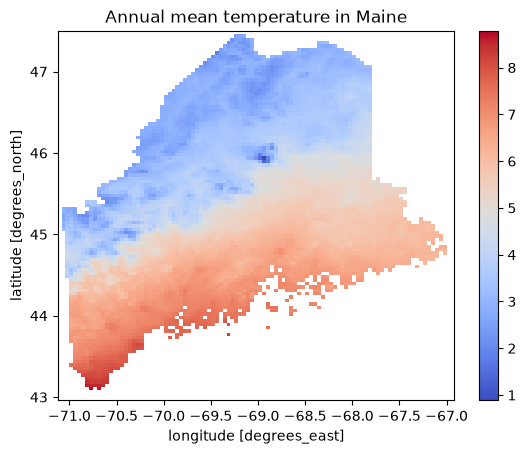

In [14]:
# Plot annual mean temperature for Maine.
bio1_maine.plot(cmap="coolwarm")
plt.title("Annual mean temperature in Maine")
plt.show()

## 5. Load and prepare amphibian occurrence records

Read the tab-delimited amphibian file. Keep `gbifID`, `species`, longitude, latitude, coordinate uncertainty, and year. Convert coordinates to numeric values and remove records missing species or coordinates.

In [15]:
amphibians = pd.read_csv(
    "Amphibians_ME/Amphibians_ME.csv",
    sep='\t',
    low_memory=False,
)

columns_to_keep = [
    "gbifID",
    "species",
    "decimalLongitude",
    "decimalLatitude",
    "coordinateUncertaintyInMeters",
    "year",
]

# Keep only columns_to_keep.
# Convert longitude and latitude to numeric values.
# Drop records missing species, longitude, or latitude.
amphibians = amphibians[columns_to_keep].copy()
amphibians["decimalLongitude"] = pd.to_numeric(amphibians["decimalLongitude"], errors="coerce")
amphibians["decimalLatitude"] = pd.to_numeric(amphibians["decimalLatitude"], errors="coerce")

# Simple cleaning
amphibians = amphibians.dropna(subset=["species", "decimalLongitude", "decimalLatitude"]).copy()

# Reduce spatial imprecision (The "tulipifera-ike" filter!)
amphibians = amphibians[amphibians["coordinateUncertaintyInMeters"] < 200]

amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

## 6. Choose one species

Display the most common species, then choose one species with at least 100 records. Store its scientific name as `target_species`.

In [16]:
# Display species counts.
amphibians["species"].value_counts().head(12)

species
Pseudacris crucifer          1839
Aquarana clamitans           1779
Anaxyrus americanus          1689
Boreorana sylvatica          1617
Lithobates catesbeianus      1487
Ambystoma maculatum          1317
Plethodon cinereus           1283
Lithobates palustris         1049
Dryophytes versicolor         790
Notophthalmus viridescens     611
Lithobates pipiens            326
Hemidactylium scutatum        233
Name: count, dtype: int64

In [18]:
target_species = "Lithobates pipiens"

# Filter the occurrence table to your target species.
# Display the number of records and the first five rows.
presence = amphibians.loc[amphibians["species"] == target_species].copy()
print(target_species)
print(presence.shape)
presence.head()

Lithobates pipiens
(326, 6)


,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year
79,6520016517,Lithobates pipiens,-67.893790,45.973465,31.0,2026.0
143,6519515940,Lithobates pipiens,-68.765251,44.823985,33.0,2026.0
321,6518356678,Lithobates pipiens,-68.806008,44.930442,6.0,2026.0
383,6500128885,Lithobates pipiens,-67.898110,45.973246,61.0,2026.0
397,6500082157,Lithobates pipiens,-68.954239,45.248262,25.0,2026.0


**Why did you choose this species?** Include one sentence about record count and one sentence about why it may or may not be appropriate for this simple model. This species has 326 counts, and that makes it appropiate for having a large enough n to view distribution trends with enviromental data. 
                                                                                            

## 7. Create an occurrence GeoDataFrame

Use longitude and latitude to create point geometry. Assign `EPSG:4326`. Confirm that the occurrence CRS and raster CRS are compatible.

In [20]:
# Create presence_gdf.
# Print the occurrence CRS and raster CRS.
presence_gdf = gpd.GeoDataFrame(
    presence,
    geometry=gpd.points_from_xy(
        presence["decimalLongitude"],
        presence["decimalLatitude"],
    ),
    crs="EPSG:4326",
)

print("Occurrence CRS:", presence_gdf.crs)
print("Raster CRS:", bio1_maine.rio.crs)


Occurrence CRS: EPSG:4326
Raster CRS: EPSG:4326


**CRS check:** Explain why coordinate systems matter before extracting raster values at points.If the CRS is different then there will be offset with respect to each other. 

## 8. Extract environment at occurrence points

Create `xarray.DataArray` objects for point longitude and latitude. Use `.sel(..., method="nearest")` to extract BIO1 values at occurrence records. Add the extracted values to a column named `bio1_c`.

In [21]:
# Create point_x and point_y.
# Extract temperature values.
# Add them to presence_gdf as bio1_c.
# Drop records with missing bio1_c.
# Rebuild point_x and point_y after dropping missing values.

point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")

presence_temp = bio1_maine.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)

presence_gdf["bio1_c"] = presence_temp.values
presence_gdf = presence_gdf.dropna(subset=["bio1_c"]).copy()

# Rebuild these after dropping missing raster values so later extractions align.
point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")

presence_gdf[["species", "decimalLongitude", "decimalLatitude", "bio1_c"]].head()

,species,decimalLongitude,decimalLatitude,bio1_c
79,Lithobates pipiens,-67.893790,45.973465,4.692000
143,Lithobates pipiens,-68.765251,44.823985,7.003333
321,Lithobates pipiens,-68.806008,44.930442,6.328500
383,Lithobates pipiens,-67.898110,45.973246,4.692000
397,Lithobates pipiens,-68.954239,45.248262,5.606000


## 9. Summarize occurrence environment

Calculate the count, mean, standard deviation, minimum, and maximum of `bio1_c` at occurrence records.

In [22]:
# Summarize occurrence temperature values.
presence_mean = presence_gdf["bio1_c"].mean()
presence_sd = presence_gdf["bio1_c"].std()

print(f"Number of usable records: {len(presence_gdf)}")
print(f"Mean occurrence temperature: {presence_mean:.2f} C")
print(f"SD of occurrence temperature: {presence_sd:.2f} C")
print(f"Minimum occurrence temperature: {presence_gdf['bio1_c'].min():.2f} C")
print(f"Maximum occurrence temperature: {presence_gdf['bio1_c'].max():.2f} C")


Number of usable records: 325
Mean occurrence temperature: 6.09 C
SD of occurrence temperature: 0.81 C
Minimum occurrence temperature: 3.01 C
Maximum occurrence temperature: 7.02 C


**Interpretation:** In two or three sentences, describe the environmental range represented by your species records. The temperature range for the selected species is from 3.01 to 7.02°C. The mean temperature of 325 records is 6.09 °C, with a SD of 0.81 °C. 

## 10. Sample background environment

Create a random sample of up to 5,000 valid cells from Maine for your environmental variable. Use a random seed so your results are reproducible.

In [26]:
rng = np.random.default_rng(597)

# Create an array of valid raster environmental values.
# Randomly sample up to 5000 cells without replacement.
# Print the background sample size, mean, and standard deviation.

valid_temperature = bio1_maine.values
valid_temperature = valid_temperature[np.isfinite(valid_temperature)]

background_temp = rng.choice(
    valid_temperature,
    size=min(5000, valid_temperature.size),
    replace=False,
)

print(f"Background sample size: {len(background_temp)}")
print(f"Mean background temperature: {background_temp.mean():.2f} C")
print(f"SD background temperature: {background_temp.std():.2f} C")

Background sample size: 5000
Mean background temperature: 4.84 C
SD background temperature: 1.58 C


## 11. Compare occurrence and background environments

Make overlapping histograms of occurrence environment and background environment. Use density-scaled histograms so the shapes can be compared even though the sample sizes differ.

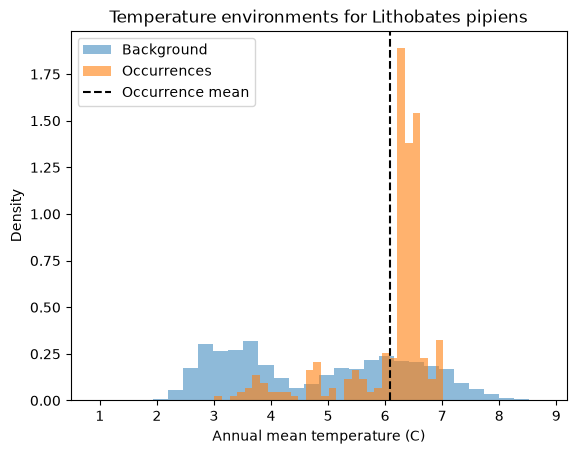

In [27]:
plt.hist(background_temp, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_gdf["bio1_c"], bins=30, alpha=0.6, density=True, label="Occurrences")
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Annual mean temperature (C)")
plt.ylabel("Density")
plt.title(f"Temperature environments for {target_species}")
plt.legend()
plt.show()

**Interpretation:** Does your species appear to use a narrow or broad subset of available environmental space? Explain using your plot. The species uses a very narrow subset of the available environmental space.

## 12. Define a suitability function

Write a function that takes `observed`, `optimum`, and `tolerance` and returns:

```python
np.exp(-0.5 * ((observed - optimum) / tolerance) ** 2)
```

This creates a score near 1 when observed environment is close to the optimum and closer to 0 as temperature gets farther away.

In [29]:
def environmental_suitability(observed, optimum, tolerance):
    suitability = np.exp(-0.5 * ((observed - optimum) / tolerance) ** 2)
    return suitability

## 13. Plot your suitability curve

Use the mean occurrence environmental value as the optimum and the standard deviation of occurrence as the tolerance. Plot suitability across the full range of Maine BIO1 values.

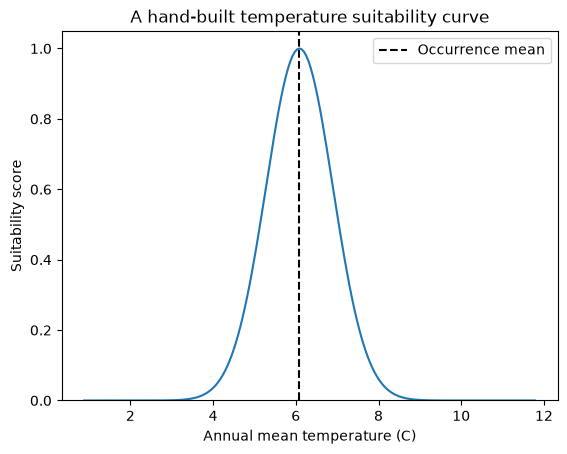

In [31]:
# Calculate presence_mean and presence_sd.
# Create a sequence of environmental values across the raster range.
# Calculate suitability for those values.
# Plot the curve.


x_temp = np.linspace(
    float(np.nanmin(bio1_maine.values)),
    float(np.nanmax(bio1_maine.values)+3),
    200,
)

suitability_curve = environmental_suitability(
    x_temp,
    optimum=presence_mean,
    tolerance=presence_sd,
)

plt.plot(x_temp, suitability_curve)
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Annual mean temperature (C)")
plt.ylabel("Suitability score")
plt.ylim(0, 1.05)
plt.title("A hand-built temperature suitability curve")
plt.legend()
plt.show()

**Interpretation:** What value receives the highest suitability score? What does the tolerance control? Around 6°C is the highest suitability. the tolerance can be interpreted as how much variance there is from the mean.

## 14. Project suitability across Maine

Apply your suitability function to every cell in the environmental raster. Keep missing raster cells missing.

In [33]:
# Use xr.apply_ufunc() to apply environmental_suitability to the raster.
# Store the result as suitability.
# Mask cells where the environmental raster is missing.

suitability = xr.apply_ufunc(
    environmental_suitability,
    bio1_maine,
    presence_mean,
    presence_sd,
)

suitability = suitability.where(np.isfinite(bio1_maine))
suitability = suitability.rio.write_crs(bio1_maine.rio.crs)
suitability.name = "temperature_suitability"
suitability

<xarray.DataArray 'temperature_suitability' (y: 109, x: 101)> Size: 88kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(109, 101))
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  31.166666030884
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -54.759166717529
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 15. Map suitability

Create a continuous suitability map with values from 0 to 1.

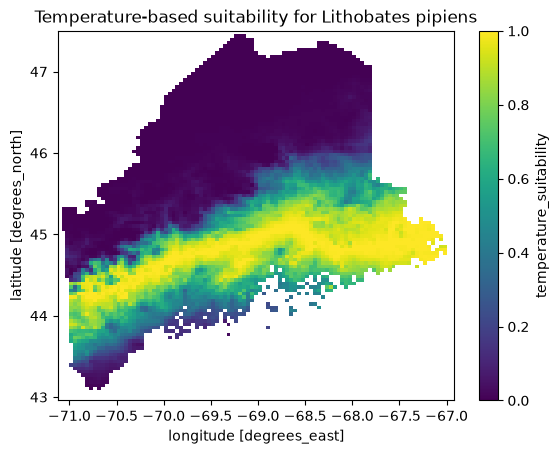

In [34]:
# Plot the suitability raster.
suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Temperature-based suitability for {target_species}")
plt.show()

## 16. Overlay occurrence points

Plot your suitability raster and overlay the occurrence points. This is a visual check, not a formal validation.

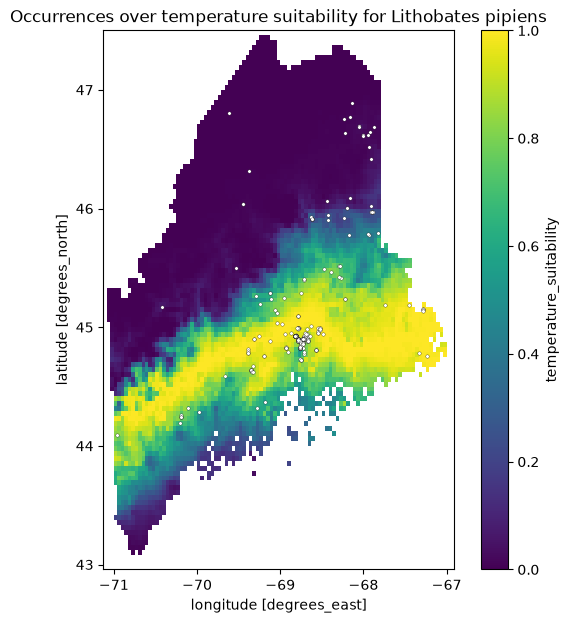

In [35]:
# Plot suitability and overlay presence_gdf points.
fig, ax = plt.subplots(figsize=(7, 7))
suitability.plot(ax=ax, vmin=0, vmax=1, cmap="viridis")
presence_gdf.plot(ax=ax, markersize=6, color="white", edgecolor="black", linewidth=0.2)
ax.set_title(f"Occurrences over temperature suitability for {target_species}")
plt.show()

**Visual check:** Do occurrence points generally fall in areas with higher predicted suitability? Describe any mismatch you see. Yes, most records fall in the high suitability zones, although there are points in the low suitability zones. 

## 17. Compare occurrence and background suitability scores

Extract suitability at occurrence records. Also calculate suitability for your background environmental values. Compare the two distributions with histograms.

Mean occurrence suitability: 0.780
Mean background suitability: 0.368


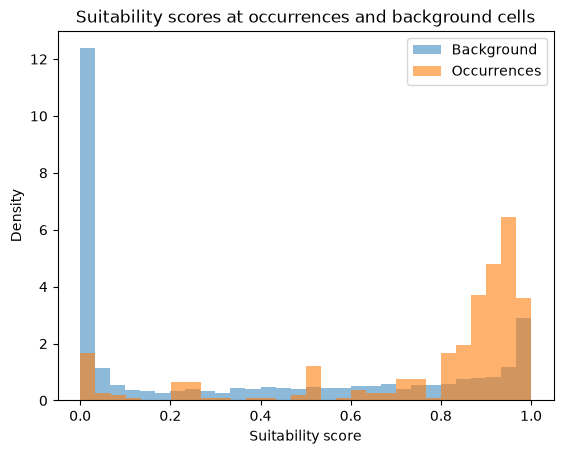

In [36]:
# Extract suitability at occurrence points.
# Calculate suitability for background environmental values.
# Print mean occurrence suitability and mean background suitability.
# Plot overlapping histograms.

presence_suitability = suitability.sel(
    x=point_x,
    y=point_y,
    method="nearest",
).values

background_suitability = environmental_suitability(
    background_temp,
    optimum=presence_mean,
    tolerance=presence_sd,
)

print(f"Mean occurrence suitability: {np.nanmean(presence_suitability):.3f}")
print(f"Mean background suitability: {np.nanmean(background_suitability):.3f}")

plt.hist(background_suitability, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_suitability, bins=30, alpha=0.6, density=True, label="Occurrences")
plt.xlabel("Suitability score")
plt.ylabel("Density")
plt.title("Suitability scores at occurrences and background cells")
plt.legend()
plt.show()

**Interpretation:** Did your model score occurrence records higher than background locations? What would it mean if it did not? The mean of the occurence records was higher than the background. If it where not this way then the there would be very little suitability for that species in Maine.

## 18. Change the tolerance

Create two additional suitability rasters: one with half the observed standard deviation and one with twice the observed standard deviation. Map all three side by side.

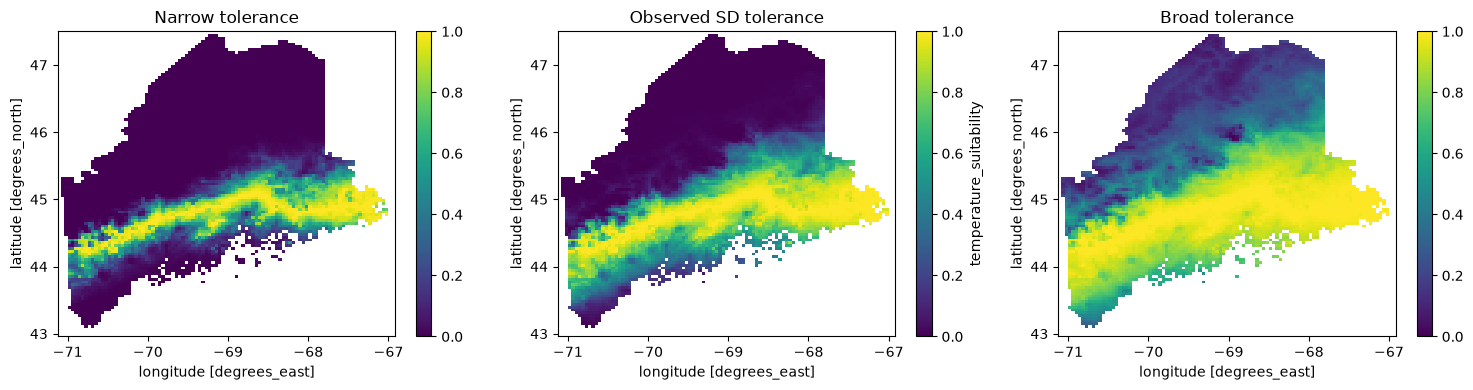

In [39]:
# Create narrow_suitability using presence_sd / 2.
# Create broad_suitability using presence_sd * 2.
# Plot narrow, original, and broad suitability maps side by side.
narrow_suitability = xr.apply_ufunc(
    environmental_suitability,
    bio1_maine,
    presence_mean,
    presence_sd / 2,
).where(np.isfinite(bio1_maine))

broad_suitability = xr.apply_ufunc(
    environmental_suitability,
    bio1_maine,
    presence_mean,
    presence_sd * 2,
).where(np.isfinite(bio1_maine))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
narrow_suitability.plot(ax=axes[0], vmin=0, vmax=1, cmap="viridis")
axes[0].set_title("Narrow tolerance")
suitability.plot(ax=axes[1], vmin=0, vmax=1, cmap="viridis")
axes[1].set_title("Observed SD tolerance")
broad_suitability.plot(ax=axes[2], vmin=0, vmax=1, cmap="viridis")
axes[2].set_title("Broad tolerance")
plt.tight_layout()
plt.show()

**Interpretation:** How does tolerance affect the predicted distribution? Which tolerance seems most defensible for your species, and why? The tolerance will determine how far on close to the mean value the model describes suitability. I would imagine that the most conservative estimate would be the narrow tolerance. However, seeing that the there is occurence records where the broader tolerance places suitability, I think that that would be the most appropiate. 

## 19. Threshold the continuous map

Convert your continuous suitability map to a binary suitable/unsuitable map using a threshold of your choice. Report the fraction of Maine climate cells labeled suitable.

Threshold 0.05: 56.70% of valid Maine climate cells suitable
Threshold 0.5: 38.44% of valid Maine climate cells suitable
Threshold 0.95: 12.07% of valid Maine climate cells suitable


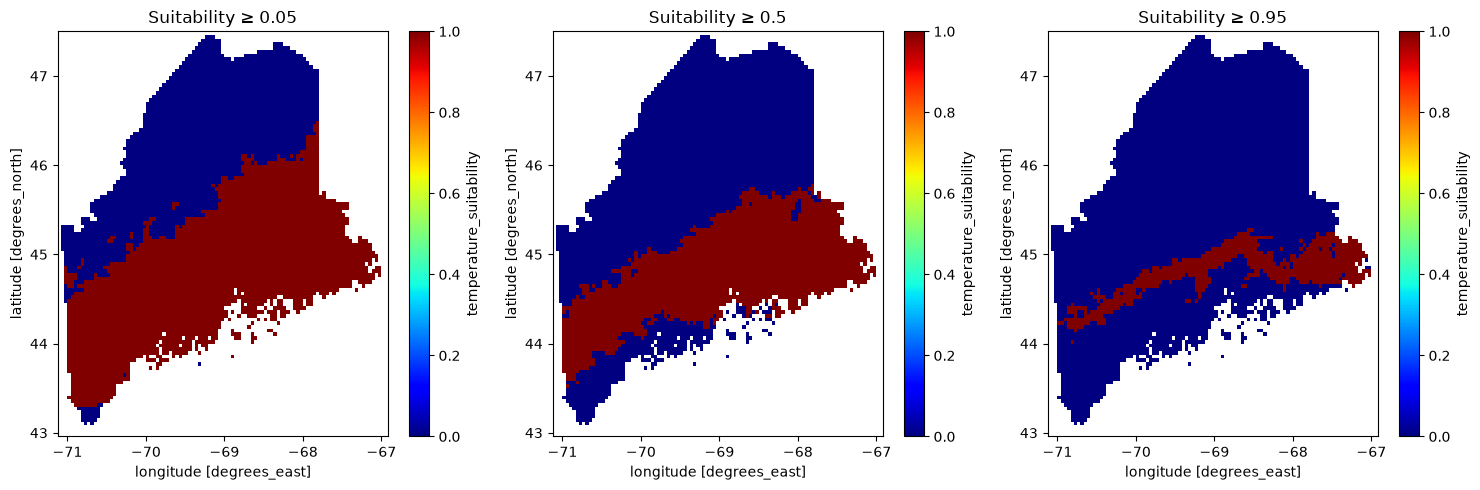

In [41]:

# Create a binary suitability map.
# Plot it.
# Calculate the fraction of non-missing cells labeled suitable.

thresholds = [0.05, 0.5, 0.95]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, threshold in zip(axes, thresholds):
    suitable_binary = (suitability >= threshold).where(
        np.isfinite(bio1_maine) & np.isfinite(suitability)
    )

    suitable_binary.plot(ax=ax, cmap="jet", vmin=0, vmax=1)
    ax.set_title(f"Suitability ≥ {threshold}")

    suitable_fraction = float(suitable_binary.mean(skipna=True))
    print(
        f"Threshold {threshold}: "
        f"{suitable_fraction:.2%} of valid Maine climate cells suitable"
    )

plt.tight_layout()
plt.show()

**Threshold justification:** Why did you choose this threshold? How would the map change with a lower or higher threshold? I wanted to plot the full confidence range and see the both extremes. 

## 20. Save your outputs

Save your continuous suitability raster as `Assignment06_suitability.tif`. Save a CSV containing your occurrence records and extracted BIO1 values as `Assignment06_presence.csv`.

In [42]:
# Save the suitability raster.
# Save the occurrence table with extracted temperature values.

suitability.rio.to_raster("Assignment06_temperature_suitability.tif")

presence_table = presence_gdf.drop(columns="geometry")
presence_table["temperature_suitability"] = presence_suitability
presence_table.to_csv("Assignment06_presence_temperature_suitability.csv", index=False)

## Final reflection

Answer each question in two or three sentences.

1. In this exercise, what information came from occurrence records and what information came from the environmental raster? The occurence of the amphibian in Maie came from the Gbif record and the raster of temperature in maine came from the environmental raster.
2. Why did we compare occurrence environment with background environment? We compared these to make sure that the occurence was within a possible range that is found in Maine. 
3. Why is this suitability score not the same as probability of presence? Suitability is only refering to the variables measured, whereas probability of presence may depend on more or different variables.
4. Name two ecological or sampling processes ignored by this one-variable model. Processes ignored are distance to roads for sampling and humidity which is very important for amphibians. 
5. What would a full SDM package add beyond this first-principles workflow? It would incorporate more considerations like road distance and biologically relevant variables. 

## Submit your work

Run the notebook from top to bottom. Make sure all maps, plots, saved files, and written answers are complete. Then commit and push the completed notebook to your class GitHub repository.

```bash
git add docs/assignments/Assignment-06-FirstPrinciplesSDM.ipynb
git commit -m "Complete first principles SDM assignment"
git push
```